# # 05 - Explainability (SHAP) and Probability Calibration

> **This notebook is part of the SleepHealth-AI project.**
> It is executed against the *production* pipeline in `src/`, so every number
> below is the same number reported in `REPORT.md`, `results/metrics/metrics.json`
> and the Streamlit app. Each final cell **asserts** that agreement, so this
> notebook cannot silently drift from the shipped system.

**Setup:** run this notebook from the `notebooks/` folder. The first cell moves
the working directory to the repository root and puts `src/` on `sys.path`.


Two questions the models must answer beyond *how accurate*:

1. **Why** did the model give this person that risk? -> SHAP
2. **Can the risk number be trusted as a probability?** -> calibration

### Why calibration is needed here

`class_weight="balanced"` is used because the targets are imbalanced. It makes the model rank people well, but its raw probabilities become badly *over-confident*. On heart disease a raw score of **0.84** corresponded to a true event rate of only **~0.34**. Cross-fitted **isotonic regression** maps those raw scores onto observed frequencies.

**Calibration cannot change ranking**, so ROC-AUC is theoretically unchanged; the Brier score is what improves.

In [1]:
# --- Reproducibility setup: run from notebooks/, work from the repo root ------
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # launched inside notebooks/
    ROOT = ROOT.parent
os.chdir(ROOT)                        # src/ scripts use repo-root-relative paths
sys.path.insert(0, str(ROOT / "src")) # so `import train_models` works

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Notebooks need the INLINE backend so plt.show() embeds the figure in the
# output. (The src/ scripts use "Agg" because they save PNGs to disk instead;
# copying that here would make every plot render as nothing.)
%matplotlib inline

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

print("repo root :", ROOT)
print("python    :", sys.version.split()[0])
print("pandas    :", pd.__version__)


repo root : C:\Users\Shubham\Desktop\SleepHealth-AI
python    : 3.13.2
pandas    : 3.0.6


In [2]:
import joblib, shap
from feature_labels import display_feature
from calibrate_models import ece
from train_models import TASKS, make_scaler_only

calib = json.load(open('results/metrics/calibration.json', encoding='utf-8'))
print('calibration method:', calib['method'])

calibration method: cross-fitted isotonic regression on out-of-fold predictions


C:\Users\Shubham\Desktop\SleepHealth-AI\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### SHAP: which features drive each risk?

Background dataset has 8281 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=8281 when initializing the masker.


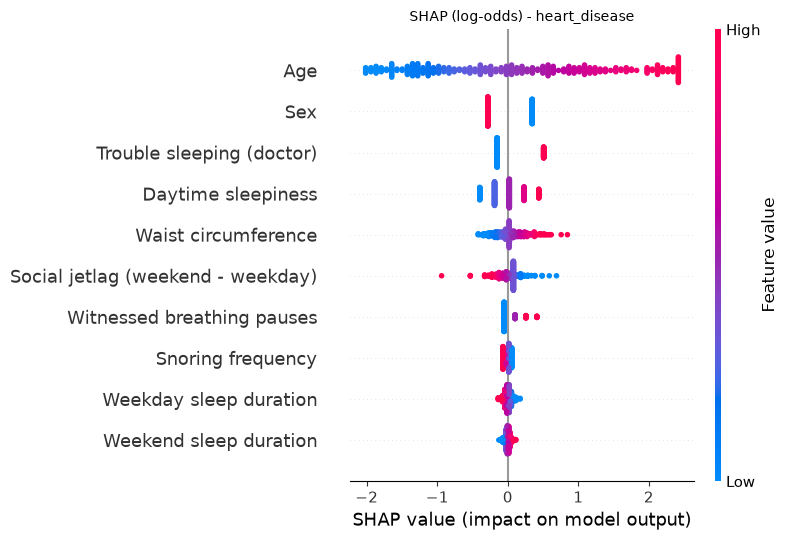

Background dataset has 8275 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=8275 when initializing the masker.


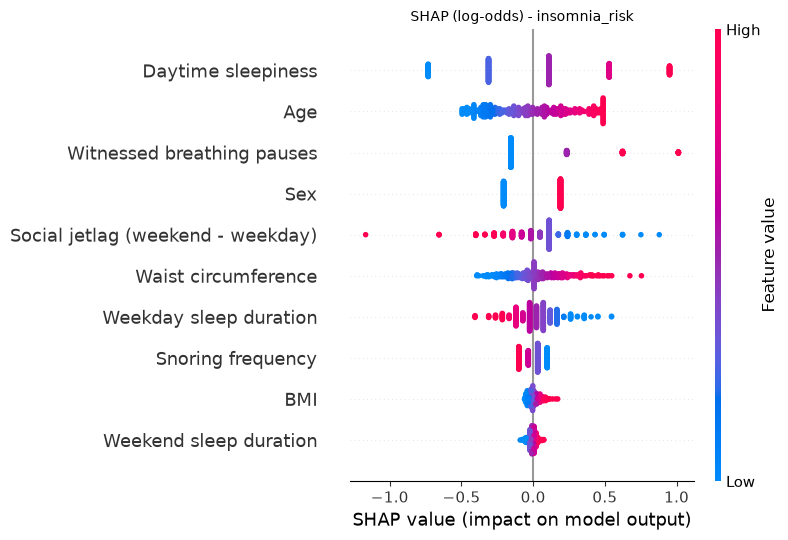

Background dataset has 7444 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=7444 when initializing the masker.


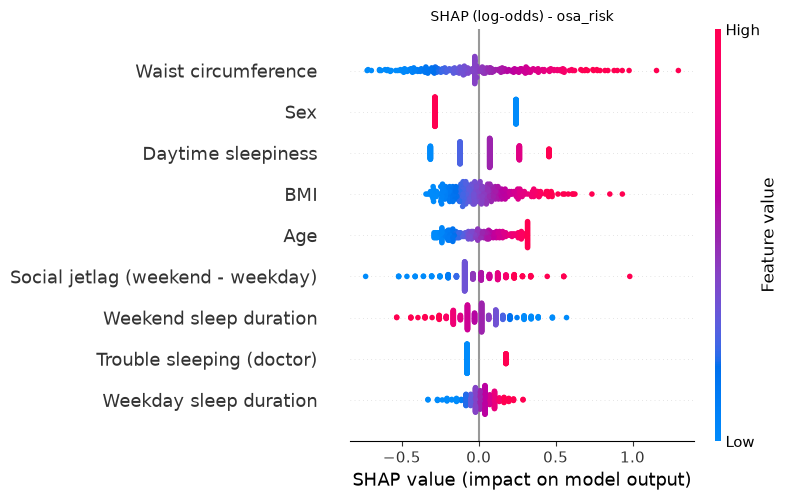

In [3]:
# SHAP summary for each of the three core tasks, using the deployed
# pickle. Feature names are human-readable via feature_labels.py.
for task_name in ['heart_disease', 'insomnia_risk', 'osa_risk']:
    task = TASKS[task_name]
    feats = task['model_b']
    d = pd.read_csv(tm_data := 'data/processed/nhanes_sleep_health.csv')
    d = d.dropna(subset=[task['target']])
    X = d[feats]
    model = joblib.load(f'models/{task_name}_model.pkl')
    Xs = np.asarray(make_scaler_only().fit_transform(X))
    mdl = model.named_steps['classifier']
    try:
        explainer = shap.TreeExplainer(mdl)
    except Exception:
        from sklearn.linear_model import LogisticRegression
        assert isinstance(mdl, LogisticRegression)
        explainer = shap.LinearExplainer(mdl, Xs)
    vals = explainer.shap_values(Xs[:300])
    if isinstance(vals, list):
        vals = vals[1]
    elif getattr(vals, 'ndim', 0) == 3:
        vals = vals[:, :, 1]
    shap.summary_plot(np.asarray(vals), Xs[:300],
                      feature_names=[display_feature(f) for f in feats],
                      show=False, max_display=10)
    plt.title(f'SHAP (log-odds) - {task_name}', fontsize=10)
    plt.tight_layout(); plt.show()

SHAP values are on the **log-odds** scale: a value of +0.69 roughly doubles the odds. Red pushes the estimate up, green down.

### Calibration: before vs after

In [4]:
names = ['heart_disease', 'insomnia_risk', 'osa_risk']
cal_tbl = pd.DataFrame({
    'Brier before': [calib[t]['brier_before'] for t in names],
    'Brier after': [calib[t]['brier_after'] for t in names],
    'ECE (equal-freq) before': [calib[t]['ece_equalfreq_before'] for t in names],
    'ECE (equal-freq) after': [calib[t]['ece_equalfreq_after'] for t in names],
    'ROC-AUC before': [calib[t]['roc_auc_before'] for t in names],
    'ROC-AUC after': [calib[t]['roc_auc_after'] for t in names],
}, index=names)
cal_tbl.round(4)

,Brier before,Brier after,ECE (equal-freq) before,ECE (equal-freq) after,ROC-AUC before,ROC-AUC after
heart_disease,0.1803,0.0740,0.2762,0.0048,0.8196,0.8134
insomnia_risk,0.2169,0.1818,0.1853,0.0129,0.7071,0.7043
osa_risk,0.2223,0.1972,0.1584,0.0126,0.6911,0.6861


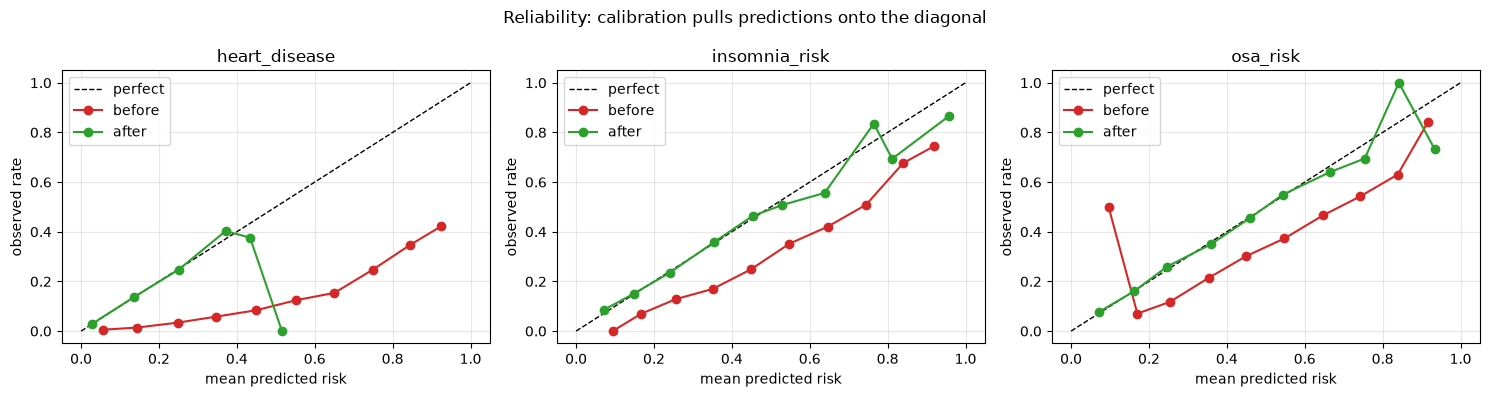

In [5]:
# Reliability curves: predicted risk vs observed frequency.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, t in zip(axes, names):
    before, after = calib[t]['reliability_before'], calib[t]['reliability_after']
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
    ax.plot([b['mean_predicted'] for b in before],
            [b['observed_rate'] for b in before], 'o-', color='tab:red',
            label='before')
    ax.plot([b['mean_predicted'] for b in after],
            [b['observed_rate'] for b in after], 'o-', color='tab:green',
            label='after')
    ax.set_title(t); ax.set_xlabel('mean predicted risk')
    ax.set_ylabel('observed rate'); ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('Reliability: calibration pulls predictions onto the diagonal')
plt.tight_layout(); plt.show()

### Verify the reported calibration numbers

The ECE function is re-checked here, including the regression guard that proves the metric is the honest (absolute-gap) variant rather than the signed version that let over- and under-prediction cancel.

In [6]:
# Guard 1: ECE must not be the error-cancelling signed variant.
rng = np.random.default_rng(0)
y_bad = rng.binomial(1, 0.5, 4000)
p_bad = np.clip(1 - y_bad * 0.9 + rng.normal(0, 0.02, 4000), 0, 1)  # anti-calibrated
ece_abs = ece(y_bad, p_bad, scheme='freq')
assert ece_abs > 0.3, f'abs-gap ECE should flag this model, got {ece_abs:.4f}'
print(f'OK - absolute-gap ECE flags the anti-calibrated model: {ece_abs:.4f}')

# Guard 2: heart-disease ECE before calibration is the large, honest value.
h = calib['heart_disease']
assert h['ece_equalfreq_before'] > 0.2, 'expected a large pre-calibration ECE'
assert h['ece_equalfreq_after'] < 0.05, 'expected a small post-calibration ECE'
assert h['brier_after'] < h['brier_before'], 'Brier must improve'
print(f"OK - heart_disease ECE {h['ece_equalfreq_before']:.4f} -> "
      f"{h['ece_equalfreq_after']:.4f}, Brier {h['brier_before']:.4f} -> {h['brier_after']:.4f}")

OK - absolute-gap ECE flags the anti-calibrated model: 0.9318
OK - heart_disease ECE 0.2762 -> 0.0048, Brier 0.1803 -> 0.0740


In [7]:
# Verify the deployed isotonic maps exist and are monotone (a calibrator
# that would LOWER the risk of a higher raw score would be nonsense).
grid = np.linspace(0.001, 0.999, 200)
for t in names:
    iso = joblib.load(f'models/calibration/{t}_isotonic.pkl')
    mapped = iso.predict(grid)
    assert np.all(np.diff(mapped) >= -1e-9), f'{t} calibrator is not monotone'
    print(f'OK - {t:15s} isotonic map is monotone non-decreasing')

OK - heart_disease   isotonic map is monotone non-decreasing
OK - insomnia_risk   isotonic map is monotone non-decreasing
OK - osa_risk        isotonic map is monotone non-decreasing
